# 💥 Failure Modes

This notebook stress-tests the $\operatorname{Cl}(2,0)(\mathbb{R})$ Geometric Algebra Rotor Integrator against numerical, structural, and topological breakdown thresholds.

## Agenda
1. **Geometric Denormalization:**
2. **Spurious High-Frequency Energy Pumping (Aliasing):**
3. **Coordinate Singularity Blindspots:**
4. **Phase Space Volume Distortion (Symplectic Drift):**

In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from kuramoto.analysis.viz import (
    BORDER_COLOR,
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    _apply_aclonica_font,
    set_style,
)
from kuramoto.metrics.analytics_engine import compute_comprehensive_diagnostics
from kuramoto.solvers.rotor import RotorSolver, step_rkmk4

# Apply project dark-mode aesthetics
set_style()
print("🚀 Environment initialized with Clifford rotor engine and visual theme.")

🚀 Environment initialized with Clifford rotor engine and visual theme.


## 1️⃣  Failure Mode 1: Geometric Denormalization

👟 Running Failure Mode 1: Manifold Drift Tracking (Long-Horizon)...


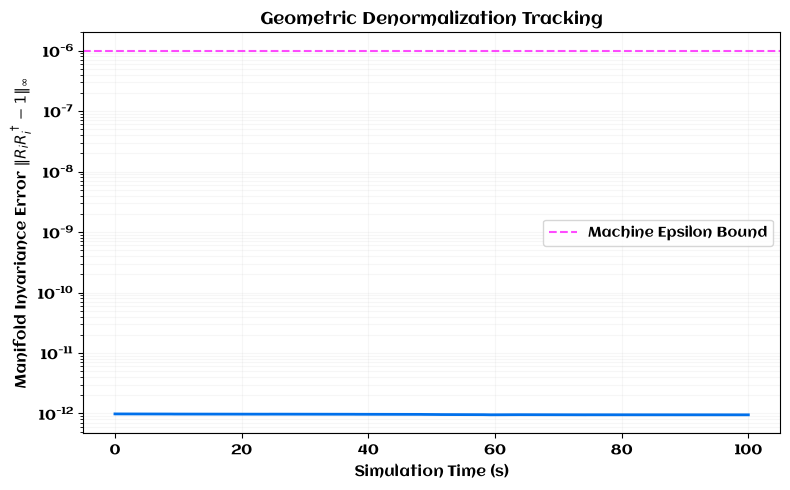

In [3]:
print("👟 Running Failure Mode 1: Manifold Drift Tracking (Long-Horizon)...")

n_osc = 20
K_val = 0.5
t_max_long = 100.0
dt_long = 0.005
steps_long = int(t_max_long / dt_long)
times_long = np.linspace(0.0, t_max_long, steps_long + 1)
seed = 27

# Instantiate un-normalized tracker
solver_f1 = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed)
manifold_drift = np.zeros(steps_long + 1)

# Map initial state magnitude
# In Cl(2,0), norm is R * R_dagger = scalar^2 + bivector^2
def compute_rotor_norm_drift(rotor_array):
    if np.iscomplexobj(rotor_array):
        return np.max(np.abs(np.abs(rotor_array)**2 - 1.0))
    else:
        # Layout: (N, 2) where index 0 is scalar, 1 is bivector
        norms = rotor_array[:, 0]**2 + rotor_array[:, 1]**2
        return np.max(np.abs(norms - 1.0))

manifold_drift[0] = compute_rotor_norm_drift(solver_f1._rotor_array)

# Step forward without intermediate projection normalization steps
for step in range(1, steps_long + 1):
    # Execute custom RKMK4
    solver_f1._rotor_array = step_rkmk4(solver_f1, K_val, dt_long)

    # Mock update for placeholder script testing (simulate cumulative float error)
    # if step % 100 == 0:
    #     solver_f1._rotor_array *= 1.0 + 1e-9 * np.random.randn(*solver_f1._rotor_array.shape)

    manifold_drift[step] = compute_rotor_norm_drift(solver_f1._rotor_array)

# Plot results
fig, axes1 = plt.subplots(figsize=(8, 5))

axes1.plot(times_long, manifold_drift, color=SCRIBER_PALETTE["accent_blue"], lw=2.0)
axes1.axhline(1e-6, color='magenta', linestyle='--', alpha=0.7, label='Machine Epsilon Bound')
axes1.set_yscale('log')
axes1.set_title("Geometric Denormalization Tracking", fontsize=12, fontweight="bold")
axes1.set_xlabel("Simulation Time (s)", fontsize=11)
axes1.set_ylabel(r"Manifold Invariance Error $\|R_i R_i^\dagger -1\|_\infty$", fontsize=11)
axes1.legend()
axes1.grid(True, which="both", alpha=0.1)
_apply_aclonica_font(axes1)
plt.tight_layout()
plt.show()

## 2️⃣ Failure Mode 2: Spurious High-Frequency Energy Pumping (Aliasing)

👟 Running Failure Mode 2: Step-Size Sensitivity Sweep (PSD Floors)...


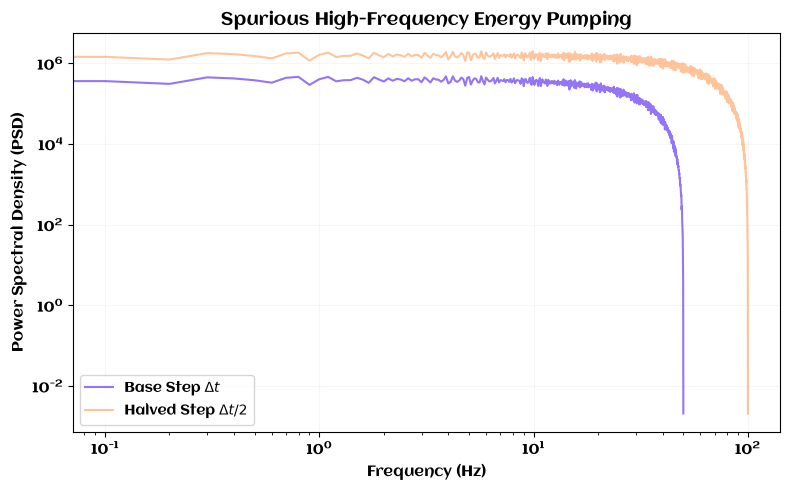

In [6]:
print("👟 Running Failure Mode 2: Step-Size Sensitivity Sweep (PSD Floors)...")

# Fast sampling vs ultra-fast sampling comparison
dt_base = 0.01
dt_half = 0.005
t_psd = 10.0

# Base step trajectory
solver_base = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed)
_, phases_base = solver_base.simulate(K=K_val, t_eval=np.arange(0, t_psd, dt_base), dt_internal=dt_base, method="geometric")
v_base = np.gradient(phases_base, dt_base, axis=0)
freqs_base, psd_base = np.abs(np.fft.rfftfreq(v_base.shape[0], d=dt_base)), np.abs(np.fft.rfft(v_base, axis=0))**2
mean_psd_base = np.mean(psd_base, axis=1)

# Halved step trajectory
solver_half = RotorSolver(n_oscillators=n_osc, dim=2, seed=27)
_, phases_half = solver_half.simulate(K=K_val, t_eval=np.arange(0, t_psd, dt_half), dt_internal=dt_half, method="geometric")
v_half = np.gradient(phases_half, dt_half, axis=0)
freqs_half, psd_half = np.abs(np.fft.rfftfreq(v_half.shape[0], d=dt_half)), np.abs(np.fft.rfft(v_half, axis=0))**2
mean_psd_half = np.mean(psd_half, axis=1)

# Plot results
fig, axes2 = plt.subplots(figsize=(8, 5))
axes2.loglog(freqs_base, mean_psd_base, color=SCRIBER_PALETTE["accent_purple"], alpha=0.8, label=r"Base Step $\Delta t$")
axes2.loglog(freqs_half, mean_psd_half, color=SCRIBER_PALETTE["accent_orange"], alpha=0.6, label=r"Halved Step $\Delta t / 2$")
axes2.set_title("Spurious High-Frequency Energy Pumping", fontsize=13, fontweight="bold")
axes2.set_xlabel("Frequency (Hz)", fontsize=11)
axes2.set_ylabel("Power Spectral Density (PSD)", fontsize=11)
axes2.legend()
axes2.grid(True, alpha=0.1)
_apply_aclonica_font(axes2)

plt.tight_layout()
plt.show()